In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
data = pd.read_csv("insurance.csv")

df = data.copy()
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
df['region'].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

In [3]:
# 1. Encode binary categoricals
df["sex"] = df["sex"].map({"male": 0, "female": 1})
df["smoker"] = df["smoker"].map({"no": 0, "yes": 1})

# 2. One-hot encode 'region' (drop_first avoids multicollinearity)
df = pd.get_dummies(df, columns=["region"], drop_first=True)

df.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,False,False,True
1,18,0,33.770,1,0,1725.55230,False,True,False
2,28,0,33.000,3,0,4449.46200,False,True,False
3,33,0,22.705,0,0,21984.47061,True,False,False
4,32,0,28.880,0,0,3866.85520,True,False,False


In [4]:
# Convert the one-hot boolean columns to 0/1
df['region_northwest'] = df['region_northwest'].map({True: 1, False: 0})
df['region_southwest'] = df['region_southwest'].map({True: 1, False: 0})
df['region_southeast'] = df['region_southeast'].map({True: 1, False: 0})

# 3. Log-transform the target
df["charges"] = np.log(df["charges"])

# 4. Split features and target
X = df.drop("charges", axis=1)
y = df["charges"]

# 5. Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set shape:", X_train.shape)
print("Feature columns:", list(X_train.columns))

print("\nSample preprocessed data:")
print(X_train.head())

# Save the splits for the modelling notebooks
X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

Training set shape: (1070, 8)
Feature columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region_northwest', 'region_southeast', 'region_southwest']

Sample preprocessed data:
      age  sex    bmi  children  smoker  region_northwest  region_southeast  \
560    46    1  19.95         2       0                 1                 0   
1285   47    1  24.32         0       0                 0                 0   
1142   52    1  24.86         0       0                 0                 1   
969    39    1  34.32         5       0                 0                 1   
486    54    1  21.47         3       0                 1                 0   

      region_southwest  
560                  0  
1285                 0  
1142                 0  
969                  0  
486                  0  


<Axes: >

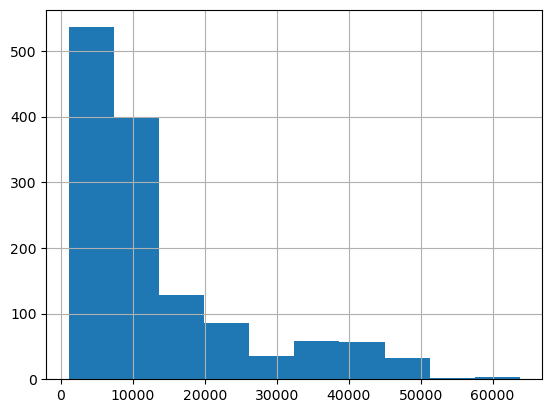

In [5]:
data['charges'].hist()

<Axes: >

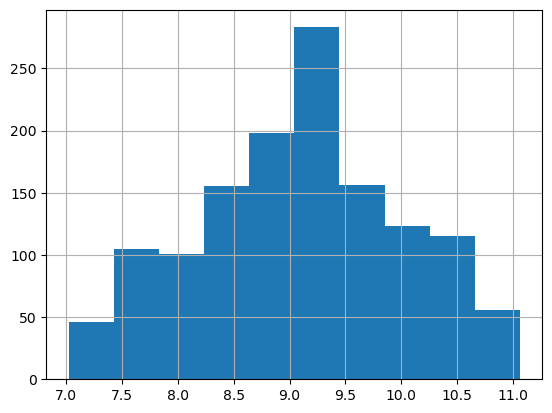

In [6]:
df['charges'].hist()

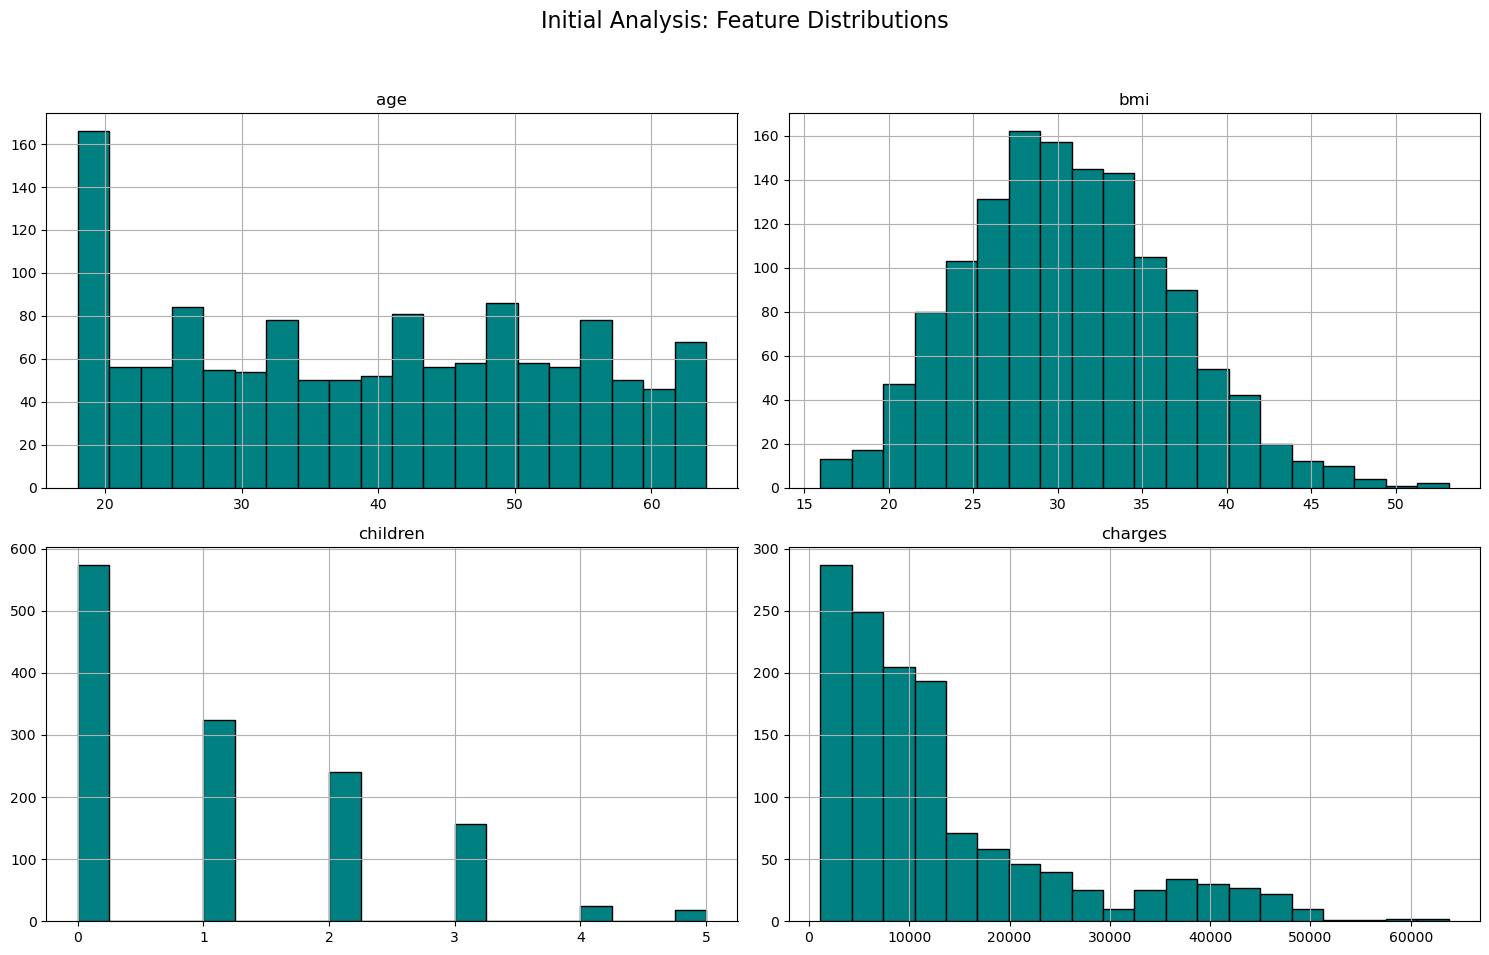

In [7]:
# Histogram of all raw features
data.hist(bins=20, figsize=(15, 10), color='teal', edgecolor='black')
plt.suptitle("Initial Analysis: Feature Distributions", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

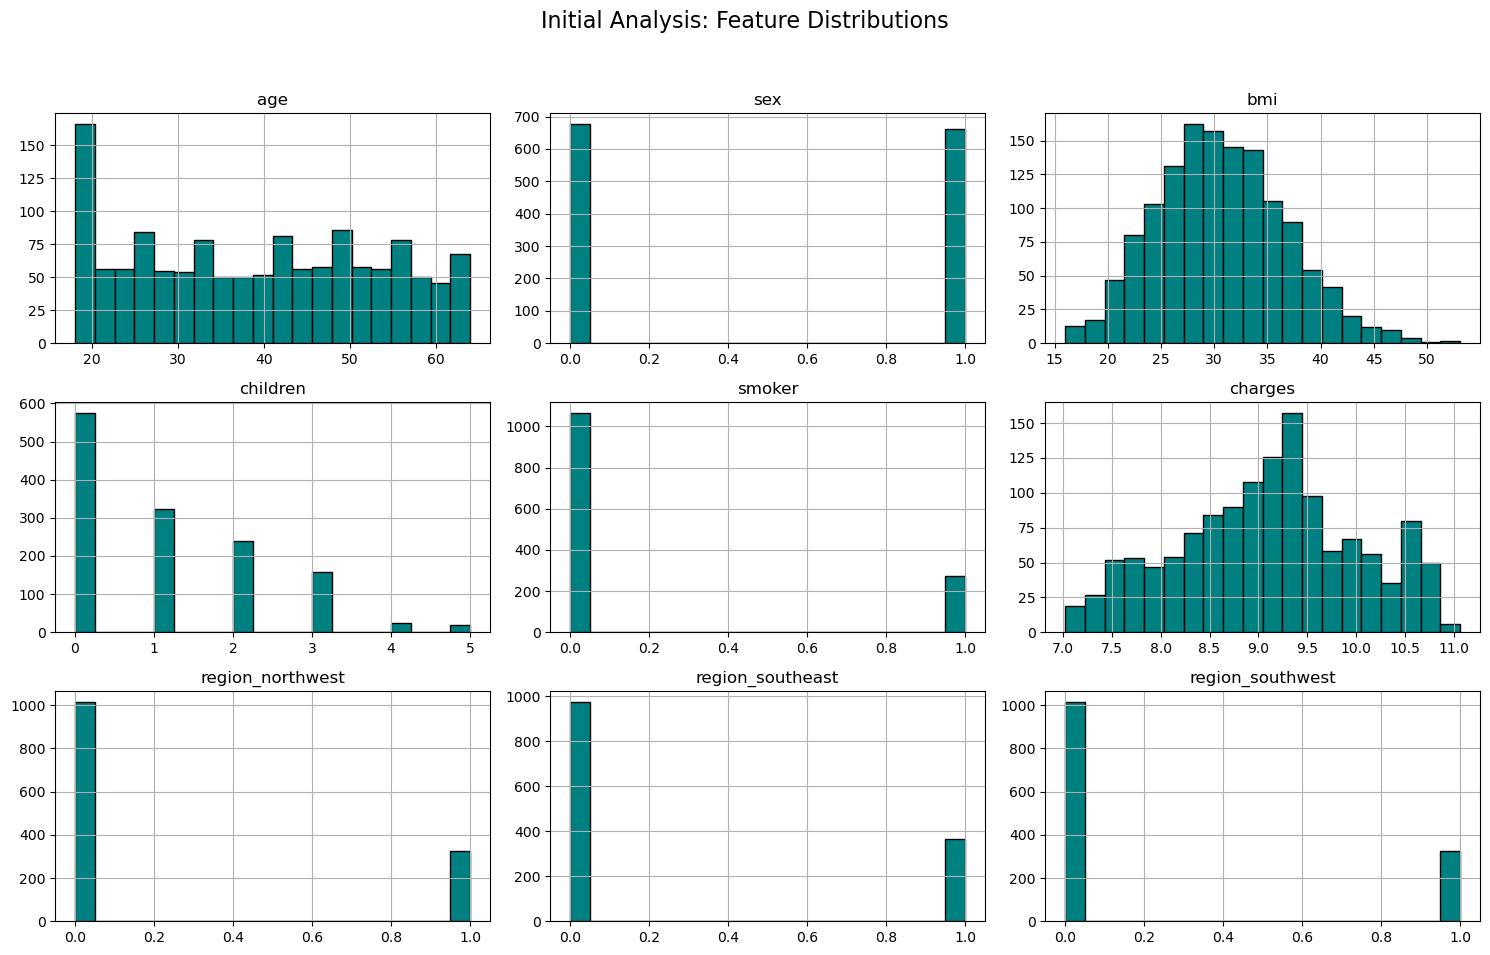

In [8]:
# Histogram of all encoded features (log-transformed charges)
df.hist(bins=20, figsize=(15, 10), color='teal', edgecolor='black')
plt.suptitle("Initial Analysis: Feature Distributions", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

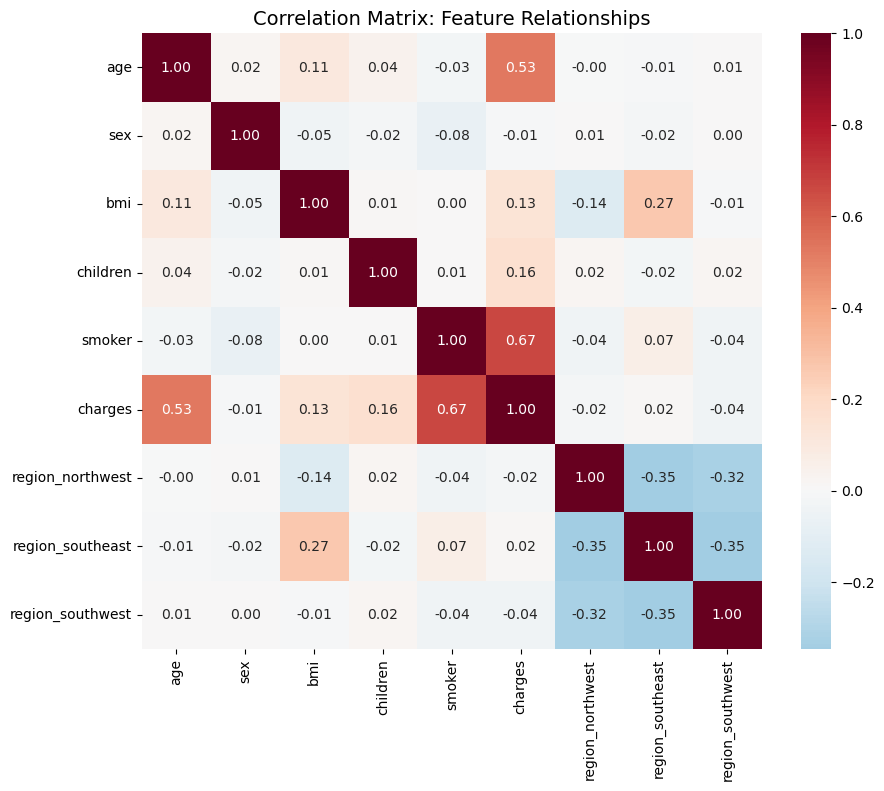

In [9]:
# Calculate the correlation matrix
corr = df.corr()

# Visualize with a Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='RdBu_r', center=0, fmt=".2f")
plt.title("Correlation Matrix: Feature Relationships", fontsize=14)
plt.show()

In [10]:
df.corr()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
age,1.000000,0.020856,0.109272,0.042469,-0.025019,0.527834,-0.000407,-0.011642,0.010016
sex,0.020856,1.000000,-0.046371,-0.017163,-0.076185,-0.005632,0.011156,-0.017117,0.004184
bmi,0.109272,-0.046371,1.000000,0.012759,0.003750,0.132669,-0.135996,0.270025,-0.006205
children,0.042469,-0.017163,0.012759,1.000000,0.007673,0.161336,0.024806,-0.023066,0.021914
smoker,-0.025019,-0.076185,0.003750,0.007673,1.000000,0.665506,-0.036945,0.068498,-0.036945
charges,0.527834,-0.005632,0.132669,0.161336,0.665506,1.000000,-0.017824,0.015791,-0.041632
region_northwest,-0.000407,0.011156,-0.135996,0.024806,-0.036945,-0.017824,1.000000,-0.346265,-0.320829
region_southeast,-0.011642,-0.017117,0.270025,-0.023066,0.068498,0.015791,-0.346265,1.000000,-0.346265
region_southwest,0.010016,0.004184,-0.006205,0.021914,-0.036945,-0.041632,-0.320829,-0.346265,1.000000


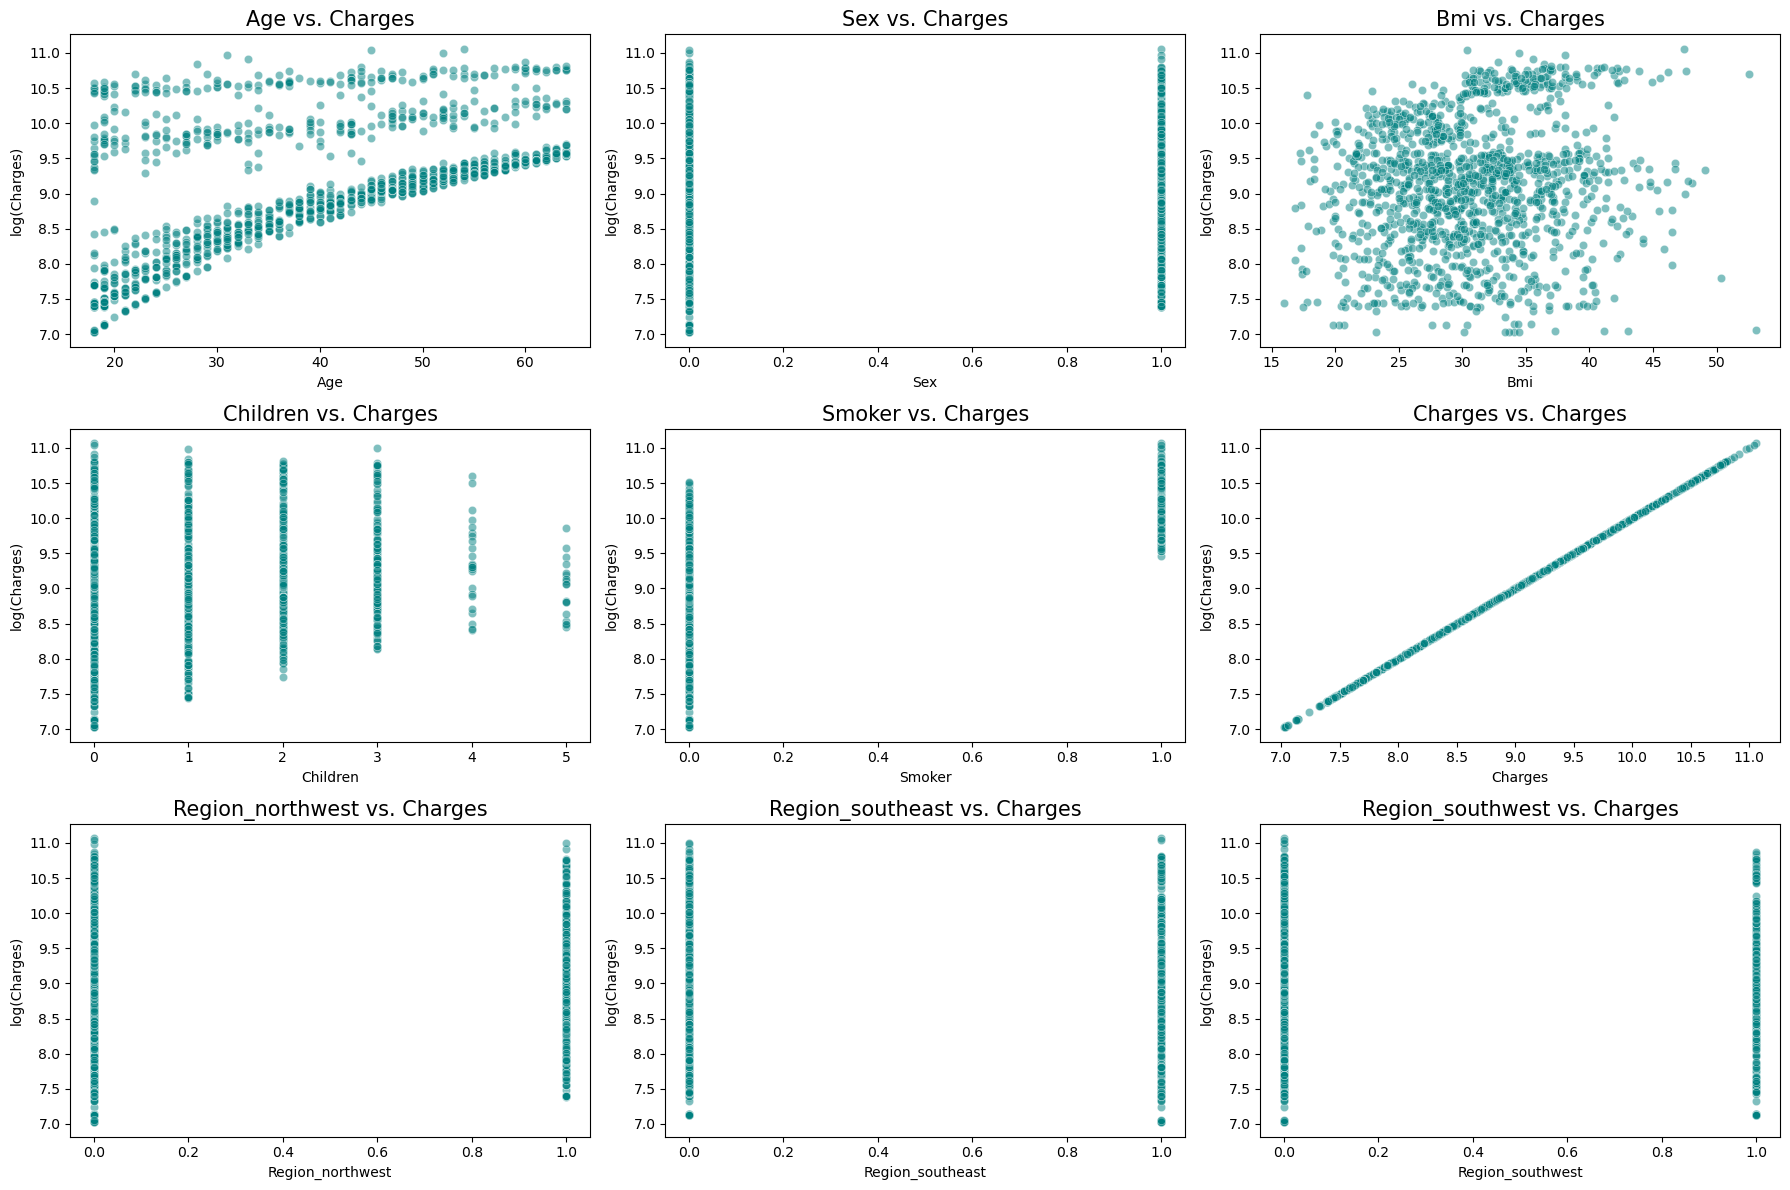

In [11]:
features = ['age', 'sex', 'bmi', 'children', 'smoker', 'charges', 'region_northwest', 'region_southeast', 'region_southwest']

# Scatter plot of each feature against log-transformed charges
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.scatterplot(data=df, x=col, y='charges', ax=axes[i], alpha=0.5, color='teal')
    axes[i].set_title(f'{col.capitalize()} vs. Charges', fontsize=15)
    axes[i].set_xlabel(col.capitalize())
    axes[i].set_ylabel('log(Charges)')

# Adjust layout so titles don't overlap
plt.tight_layout()
plt.show()

In [12]:
df.shape

(1338, 9)

In [13]:
X_train.describe()

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
count,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000
mean,39.357009,0.487850,30.560397,1.107477,0.205607,0.239252,0.264486,0.246729
std,14.073960,0.500086,6.043386,1.215983,0.404334,0.426827,0.441265,0.431309
min,18.000000,0.000000,15.960000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,27.000000,0.000000,26.205000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,39.500000,0.000000,30.210000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,51.000000,1.000000,34.496250,2.000000,0.000000,0.000000,1.000000,0.000000
max,64.000000,1.000000,53.130000,5.000000,1.000000,1.000000,1.000000,1.000000


In [14]:
data[data.duplicated()]

,age,sex,bmi,children,smoker,region,charges
581,19,male,30.59,0,no,northwest,1639.5631


In [15]:
data.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [16]:
data.shape

(1338, 7)

In [17]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [18]:
data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010
